# PART 3. 데이터 이해

## 📋 한눈에 보기

**작업 흐름**
```
1. CSV 파일 불러오기
2. 크기(행·열) 확인
3. 컬럼 확인
4. 결측치 확인
5. 테이블 연결 구조(ERD) 이해
```

| 항목 | 내용 |
|---|---|
| 핵심 질문 | 각 테이블에는 무엇이 들어 있고, 서로 어떻게 연결될까? |
| 사용 데이터 | 원본 CSV 9개 |
| 결과물 | 테이블 연결 구조 이해 (파일 저장 없음) |

**🎯 핵심 (꼭 가져갈 것)**
- 테이블은 **ID 컬럼**(order_id, product_id, seller_id …)으로 연결됩니다.
- 1:N 관계(주문 1건 ↔ 상품 여러 개)를 알아야 다음 PART의 merge 결과를 이해할 수 있습니다.

**💡 인사이트 (이 파트에서 확인한 사실)**
- orders가 중심이고, 상품·결제·리뷰는 order_id로 붙습니다.
- 한 사람의 재구매는 `customer_unique_id`로만 확인할 수 있습니다.
- 리뷰가 2개 이상인 주문이 547건 있습니다.

---

## 수업 목표
- 각 CSV 파일의 크기(행/열), 컬럼 구성, 결측치를 확인합니다.
- 어떤 컬럼(ID)을 기준으로 테이블이 서로 연결되는지 파악합니다.

## 수업 진행 포인트
| 구분 | 설명 |
|---|---|
| 데이터 관점 | 각 테이블이 어떤 정보를 담고 있는지 확인합니다. |
| 코드 관점 | shape, head(), columns, isnull() 사용법을 익힙니다. |
| AI 관점 | AI 모델링 전 반드시 데이터 구조를 이해해야 합니다. |
---

In [1]:
# 셀 1. Google Drive 연결

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 셀 2. 라이브러리 및 경로 설정

import os
import pandas as pd

base_path = "/content/drive/MyDrive/Colab Notebooks/Data_Analysis/Olist/data"
print("사용할 데이터 폴더:", base_path)

사용할 데이터 폴더: /content/drive/MyDrive/Colab Notebooks/Data_Analysis/Olist/data


In [3]:
# 셀 3. 9개 CSV 파일 모두 불러오기
# PART 2에서 저장한 파일들을 불러옵니다.

customers   = pd.read_csv(f"{base_path}/olist_customers_dataset.csv")
orders      = pd.read_csv(f"{base_path}/olist_orders_dataset.csv")
order_items = pd.read_csv(f"{base_path}/olist_order_items_dataset.csv")
products    = pd.read_csv(f"{base_path}/olist_products_dataset.csv")
payments    = pd.read_csv(f"{base_path}/olist_order_payments_dataset.csv")
reviews     = pd.read_csv(f"{base_path}/olist_order_reviews_dataset.csv")
sellers     = pd.read_csv(f"{base_path}/olist_sellers_dataset.csv")
geolocation = pd.read_csv(f"{base_path}/olist_geolocation_dataset.csv")
category    = pd.read_csv(f"{base_path}/product_category_name_translation.csv")

print("모든 파일 불러오기 완료!")

모든 파일 불러오기 완료!


In [4]:
# 셀 4. 각 파일의 크기(행 x 열) 확인
# shape = (행 개수, 열 개수)
# 행 = 데이터 수, 열 = 속성(컬럼) 수

data_dict = {
    "customers":   customers,
    "orders":      orders,
    "order_items": order_items,
    "products":    products,
    "payments":    payments,
    "reviews":     reviews,
    "sellers":     sellers,
    "geolocation": geolocation,
    "category":    category,
}

print(f"{'데이터명':<15} {'행(Row)':<12} {'열(Column)'}")
print("-" * 38)
for name, df in data_dict.items():
    rows, cols = df.shape
    print(f"{name:<15} {rows:<12,} {cols}")

데이터명            행(Row)       열(Column)
--------------------------------------
customers       99,441       5
orders          99,441       8
order_items     112,650      7
products        32,951       9
payments        103,886      5
reviews         99,224       7
sellers         3,095        4
geolocation     1,000,163    5
category        71           2


| 데이터 | 행(Row) | 열(Column) | 설명 |
|---|---|---|---|
| customers | 99,441 | 5 | 고객 정보 |
| orders | 99,441 | 8 | 주문 정보 |
| order_items | 112,650 | 7 | 주문 상품 정보 |
| products | 32,951 | 9 | 상품 정보 |
| payments | 103,886 | 5 | 결제 정보 |
| reviews | 99,224 | 7 | 리뷰 정보 |
| sellers | 3,095 | 4 | 판매자 정보 |
| geolocation | 1,000,163 | 5 | 위치 정보 |
| category | 71 | 2 | 카테고리 번역 |

> **order_items 행이 더 많은 이유:** 주문 1건에 상품이 여러 개 있을 수 있기 때문입니다.
>
> **payments 행이 더 많은 이유:** 한 주문을 신용카드 + 바우처처럼 나눠 결제할 수 있기 때문입니다.
>
> **reviews 행(99,224)이 orders(99,441)와 다른 이유:** 리뷰가 없는 주문도 있고(768건), 리뷰가 2개 이상인 주문도 있습니다(547건).

In [5]:
# 셀 5. 각 테이블의 컬럼 목록 확인
# 어떤 ID 컬럼으로 테이블이 연결되는지 파악하는 것이 핵심입니다.

for name, df in data_dict.items():
    print(f"\n[{name}]")
    print(", ".join(df.columns.tolist()))


[customers]
customer_id, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state

[orders]
order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date

[order_items]
order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value

[products]
product_id, product_category_name, product_name_lenght, product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm

[payments]
order_id, payment_sequential, payment_type, payment_installments, payment_value

[reviews]
review_id, order_id, review_score, review_comment_title, review_comment_message, review_creation_date, review_answer_timestamp

[sellers]
seller_id, seller_zip_code_prefix, seller_city, seller_state

[geolocation]
geolocation_zip_code_prefix, geolocation_lat, geolocation_lng, geolocation_city, geolocation_state

[cat

In [6]:
# 셀 6. 주요 테이블 샘플 확인

print("=== customers (고객 정보) ===")
print(customers.head(3))

print("\n=== orders (주문 정보) ===")
print(orders.head(3))

print("\n=== order_items (주문 상품) ===")
print(order_items.head(3))

=== customers (고객 정보) ===
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  

=== orders (주문 정보) ===
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-

In [7]:
# 셀 7. 결측치 확인
# 결측치(NaN) = 값이 비어있는 데이터
# 0이면 결측치 없음, 숫자가 크면 결측치 많음

print("=== reviews 결측치 현황 ===")
print(reviews.isnull().sum())
# ▶ review_comment_message: 리뷰 글 없이 점수만 남긴 경우가 많습니다.

=== reviews 결측치 현황 ===
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


## 테이블 연결 구조

```
customers ──── orders ──── order_items ──── products
                  │                └──────── sellers
                  ├──── payments
                  └──── reviews
```

| 연결 | 기준 컬럼 | 관계 |
|---|---|---|
| customers ↔ orders | customer_id | 1 : 1 (customer_id는 주문마다 새로 발급) |
| orders ↔ order_items | order_id | 1 : N (한 주문에 여러 상품) |
| orders ↔ payments | order_id | 1 : N (나눠 결제하면 여러 행) |
| orders ↔ reviews | order_id | 대부분 1 : 1 (리뷰 2개 이상인 주문 547건) |
| order_items ↔ products | product_id | N : 1 |
| order_items ↔ sellers | seller_id | N : 1 |

> 📌 **한 사람이 여러 번 주문한 것**은 `customer_id`가 아니라 `customer_unique_id`로 확인합니다.
> customer_id는 주문할 때마다 새로 만들어지므로 orders와 1:1로 연결됩니다.

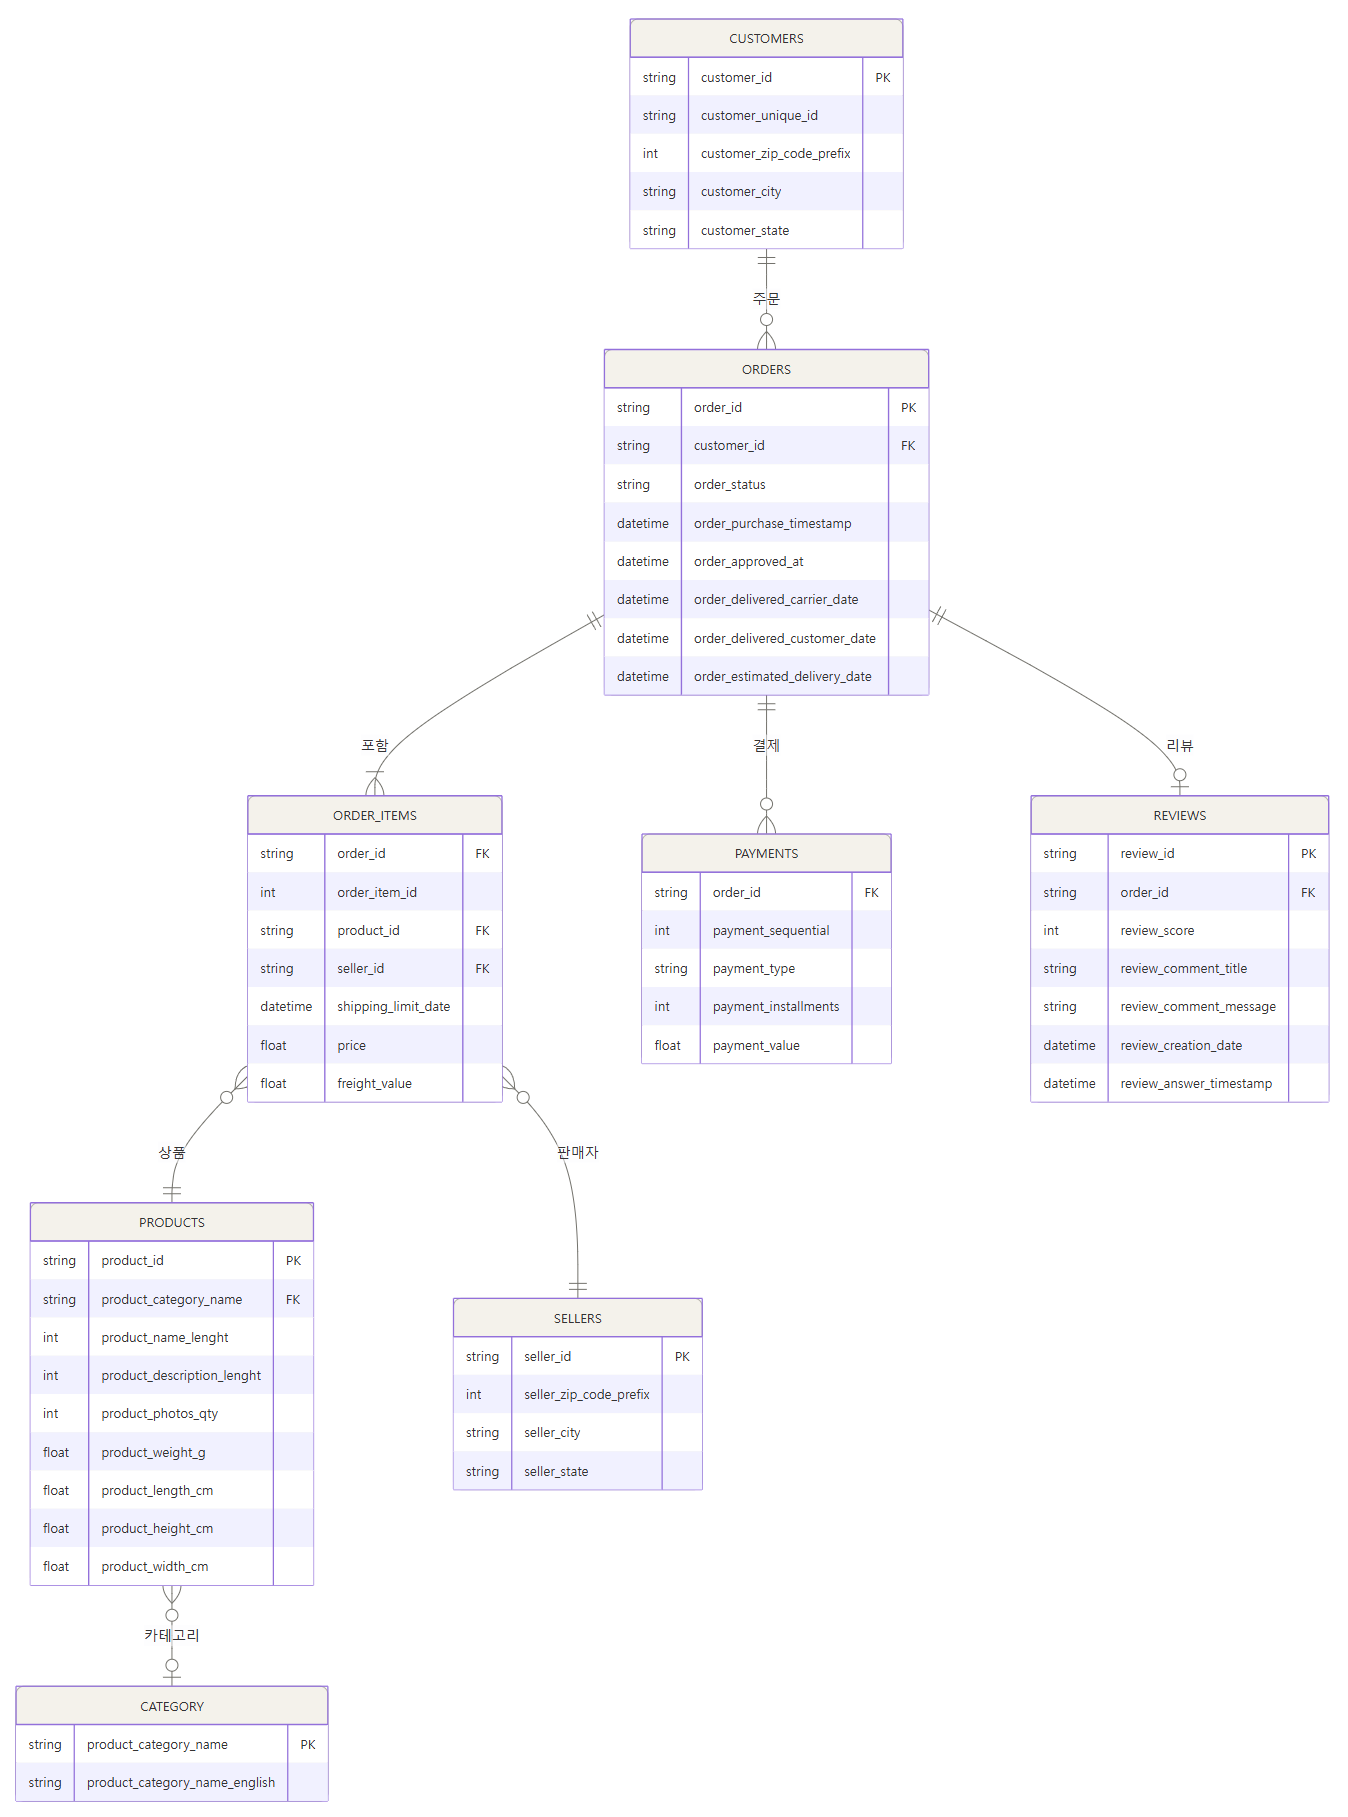

---

## 마무리 정리

| 확인할 내용 | 설명 |
|---|---|
| 이 파트의 핵심 | 각 CSV의 구조와 연결 관계를 파악합니다. |
| 다음 단계 | PART 4에서 9개 CSV를 하나로 병합(merge)합니다. |